
PM2.5
APCP used for fitting: > 0 mm
Number of points: 19
Estimated a: 0.040374
Estimated b: 0.595085
R-squared: 0.9391

PM10
APCP used for fitting: > 0 mm
Number of points: 19
Estimated a: 0.081227
Estimated b: 0.450817
R-squared: 0.9194


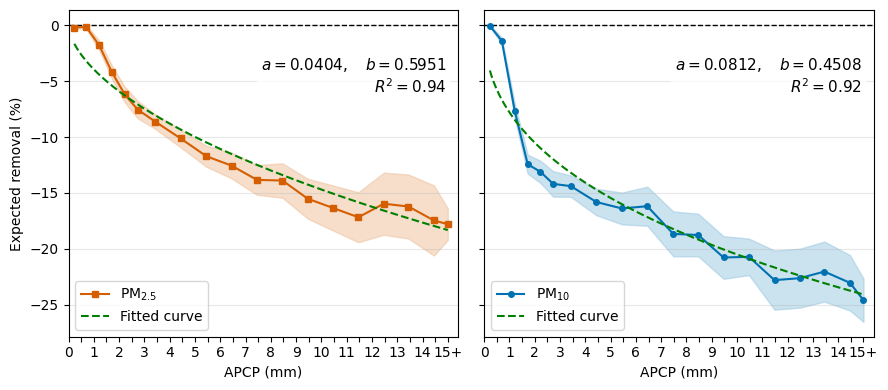

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.optimize import curve_fit

pm10 = pd.read_csv(
    r"\data\results_export\pm10\PM10_removal_by_precipitation.csv"
)
pm25 = pd.read_csv(
    r"\data\results_export\pm25\PM25_removal_by_precipitation.csv"
)

PM25_DARK, PM10_DARK = "#D55E00", "#0072B2"
PM25_LIGHT50, PM10_LIGHT50 = "#EEBF99", "#99C7E0"

pm10["pollutant"] = "PM10"
pm25["pollutant"] = "PM2.5"

df_plot = pd.concat([pm10, pm25], ignore_index=True)

styles = {
    "PM10": dict(
        color=PM10_DARK,
        ci=PM10_LIGHT50,
        marker="o",
        label=r"PM$_{10}$"
    ),
    "PM2.5": dict(
        color=PM25_DARK,
        ci=PM25_LIGHT50,
        marker="s",
        label=r"PM$_{2.5}$"
    ),
}


def washout_model(P, a, b):
    return (np.exp(-a * P**b) - 1) * 100


def tick_fmt(x, pos):
    if np.isclose(x, 15.0):
        return "15+"
    elif np.isclose(x % 1, 0):
        return f"{int(x)}"
    return ""


fig, axes = plt.subplots(
    1,
    2,
    figsize=(9, 4),
    sharey=True
)


for ax, pollutant in zip(
    axes,
    ["PM2.5", "PM10"]
):

    group = df_plot[
        df_plot["pollutant"] == pollutant
    ].copy()

    group = group.sort_values(
        "median_APCP"
    ).reset_index(drop=True)

    s = styles[pollutant]

    x_num = group[
        "median_APCP"
    ].astype(float).values

    x_plot = np.minimum(
        x_num,
        15.0
    )

    y = group[
        "mean_percent_removal"
    ].astype(float).values

    lo = group[
        "mean_percent_removal_ci_low"
    ].astype(float).values

    hi = group[
        "mean_percent_removal_ci_high"
    ].astype(float).values

    ax.fill_between(
        x_plot,
        lo,
        hi,
        color=s["ci"],
        alpha=0.5
    )

    ax.plot(
        x_plot,
        y,
        marker=s["marker"],
        color=s["color"],
        linestyle="-",
        linewidth=1.5,
        markersize=4,
        zorder=3,
        label=s["label"]
    )

    mask = (
        np.isfinite(x_num)
        & np.isfinite(y)
        & (x_num > 0)
    )

    x_fit_data = x_num[mask]
    y_fit_data = y[mask]


    popt, pcov = curve_fit(
        washout_model,
        x_fit_data,
        y_fit_data,
        p0=[0.05, 0.5],
        bounds=(
            [0, 0],
            [np.inf, np.inf]
        ),
        maxfev=10000
    )

    a_hat, b_hat = popt


    # -----------------------------------------------------
    # Calculate R-squared
    # -----------------------------------------------------
    y_pred = washout_model(
        x_fit_data,
        a_hat,
        b_hat
    )

    ss_res = np.sum(
        (y_fit_data - y_pred) ** 2
    )

    ss_tot = np.sum(
        (y_fit_data - np.mean(y_fit_data)) ** 2
    )

    r_squared = 1 - (
        ss_res / ss_tot
    )

    print(f"\n{pollutant}")
    print("APCP used for fitting: > 0 mm")
    print(f"Number of points: {len(x_fit_data)}")
    print(f"Estimated a: {a_hat:.6f}")
    print(f"Estimated b: {b_hat:.6f}")
    print(f"R-squared: {r_squared:.4f}")

    x_smooth_num = np.linspace(
        x_fit_data.min(),
        min(x_fit_data.max(), 15.0),
        300
    )

    y_smooth = washout_model(
        x_smooth_num,
        a_hat,
        b_hat
    )

    ax.plot(
        x_smooth_num,
        y_smooth,
        color="green",
        linestyle="--",
        linewidth=1.5,
        zorder=4,
        label="Fitted curve"
    )

    eq_text = (
        rf"$a={a_hat:.4f},\quad b={b_hat:.4f}$"
        "\n"
        rf"$R^2={r_squared:.2f}$"
    )

    ax.text(
        0.97,
        0.86,
        eq_text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none",
            pad=3
        )
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.grid(
        True,
        alpha=0.3,
        axis="y"
    )

    xticks = np.arange(
        0,
        15.5,
        0.5
    )

    ax.set_xticks(
        xticks
    )

    ax.xaxis.set_major_formatter(
        FuncFormatter(tick_fmt)
    )

    ax.set_xlim(
        0,
        15.4
    )

    ax.set_xlabel(
        r"APCP (mm)"
    )

    ax.legend()


axes[0].set_ylabel(
    r"Expected removal (%)"
)


plt.tight_layout()


plt.savefig(
    r"C:\Users\dneupane\PycharmProjects\DMLImplementation"
    r"\huber_plots\FIGURES\curve_fitting_distribution.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()